# Portfolio Management - Group Work Project 1: Mean-Variance Optimization, Out-of-Sample Test, Fama-French Regression and Monte Carlo

### Step 1

In [137]:
import yfinance as yf
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

In [138]:
# Define the securities and period
tickers = ["TSLA", "WMT", "BAC", "GS", "LLY", "MRK", "GOOG", "META", "AAPL", "XOM"]
start_date = "2023-07-01"
end_date = "2025-06-30"

# Download weekly data (adjusted close prices)
data = yf.download(tickers, start=start_date, end=end_date, interval="1wk")

if 'Adj Close' in data.columns.get_level_values(0):
    prices = data['Adj Close']
elif 'Close' in data.columns.get_level_values(0):
    prices = data['Close']

# Check if we have data for all tickers
print(f"\nData shape: {prices.shape}")
print(f"Number of weeks: {len(prices)}")

# Drop rows with missing values
prices = prices.dropna()
print(f"Number of weeks after dropping NaN: {len(prices)}")

[*********************100%***********************]  10 of 10 completed



Data shape: (104, 10)
Number of weeks: 104
Number of weeks after dropping NaN: 104


In [139]:
# Calculate weekly returns
returns = prices.pct_change().dropna()
print(f"\nWeekly returns shape: {returns.shape}")


Weekly returns shape: (103, 10)


In [140]:
# Calculate mean returns and covariance matrix
mean_returns = returns.mean().values
cov_matrix = returns.cov().values
n_assets = len(tickers)

print("\nMean weekly returns (%):")
print((mean_returns * 100).round(4))

print("\nAnnualized volatility (%):")
annual_vol = np.sqrt(52) * returns.std()
print((annual_vol * 100).round(2))


Mean weekly returns (%):
[ 0.1317  0.6211  0.474   0.8959  0.6642  1.0278 -0.2026  0.4937  0.6891
  0.1724]

Annualized volatility (%):
Ticker
AAPL    27.01
BAC     28.86
GOOG    29.80
GS      29.48
LLY     36.38
META    35.69
MRK     22.88
TSLA    60.20
WMT     20.47
XOM     22.49
dtype: float64


In [141]:
# Define optimization problem for Global Minimum Variance Portfolio
def portfolio_variance(weights, cov_matrix):
    """Calculate portfolio variance (objective to minimize)"""
    return np.dot(weights.T, np.dot(cov_matrix, weights))

def portfolio_return(weights, mean_returns):
    """Calculate portfolio expected return"""
    return np.dot(weights, mean_returns)

# Define constraints
constraints = [
    {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}  # weights sum to 1
]

# Define bounds (no short-selling)
bounds = [(0, 1) for _ in range(n_assets)]

# Initial guess (equal weights)
initial_weights = np.ones(n_assets) / n_assets

print("SOLVING FOR OPTIMAL MEAN-VARIANCE PORTFOLIO USING OPTIMIZATION")

SOLVING FOR OPTIMAL MEAN-VARIANCE PORTFOLIO USING OPTIMIZATION


In [142]:
# Solve for Global Minimum Variance Portfolio (GMVP)
print("\n1. GLOBAL MINIMUM VARIANCE PORTFOLIO (GMVP)")
print("   Objective: Minimize portfolio variance")

gmvp_result = minimize(
    fun=portfolio_variance,
    x0=initial_weights,
    args=(cov_matrix,),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints,
    options={'ftol': 1e-10, 'maxiter': 1000}
)

gmvp_weights = gmvp_result.x
gmvp_variance = portfolio_variance(gmvp_weights, cov_matrix)
gmvp_volatility = np.sqrt(gmvp_variance)
gmvp_expected_return = portfolio_return(gmvp_weights, mean_returns)

print(f"   Optimization successful: {gmvp_result.success}")
print(f"   Message: {gmvp_result.message}")

# Display GMVP weights
print("\n   GMVP Weights:")
for i, ticker in enumerate(tickers):
    if gmvp_weights[i] > 0.0001:  # Show non-negligible weights
        print(f"   {ticker:<6}: {gmvp_weights[i]:.4f} ({gmvp_weights[i]*100:6.2f}%)")

print(f"\n   Portfolio Statistics:")
print(f"   Expected Weekly Return:   {gmvp_expected_return:.6f} ({gmvp_expected_return*100:.4f}%)")
print(f"   Weekly Volatility:        {gmvp_volatility:.6f} ({gmvp_volatility*100:.4f}%)")
print(f"   Annualized Return:        {gmvp_expected_return*52:.4f} ({gmvp_expected_return*52*100:.2f}%)")
print(f"   Annualized Volatility:    {gmvp_volatility*np.sqrt(52):.4f} ({gmvp_volatility*np.sqrt(52)*100:.2f}%)")


1. GLOBAL MINIMUM VARIANCE PORTFOLIO (GMVP)
   Objective: Minimize portfolio variance
   Optimization successful: True
   Message: Optimization terminated successfully

   GMVP Weights:
   TSLA  : 0.0759 (  7.59%)
   BAC   : 0.0694 (  6.94%)
   GOOG  : 0.2454 ( 24.54%)
   AAPL  : 0.3228 ( 32.28%)
   XOM   : 0.2864 ( 28.64%)

   Portfolio Statistics:
   Expected Weekly Return:   0.002651 (0.2651%)
   Weekly Volatility:        0.017257 (1.7257%)
   Annualized Return:        0.1378 (13.78%)
   Annualized Volatility:    0.1244 (12.44%)


In [143]:
# Solve for Maximum Sharpe Ratio Portfolio (MSRP)
print("\n\n2. MAXIMUM SHARPE RATIO PORTFOLIO (MSRP)")
print("   Objective: Maximize Sharpe Ratio")

# Assuming annual risk-free rate of 2% (can be changed)
risk_free_rate = 0.03
weekly_rf = risk_free_rate / 52

def negative_sharpe_ratio(weights, mean_returns, cov_matrix, rf_rate):
    """Negative Sharpe ratio (to minimize)"""
    port_return = portfolio_return(weights, mean_returns)
    port_volatility = np.sqrt(portfolio_variance(weights, cov_matrix))
    sharpe = (port_return - rf_rate) / port_volatility
    return -sharpe

msrp_result = minimize(
    fun=negative_sharpe_ratio,
    x0=initial_weights,
    args=(mean_returns, cov_matrix, weekly_rf),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints,
    options={'ftol': 1e-10, 'maxiter': 1000}
)

msrp_weights = msrp_result.x
msrp_variance = portfolio_variance(msrp_weights, cov_matrix)
msrp_volatility = np.sqrt(msrp_variance)
msrp_expected_return = portfolio_return(msrp_weights, mean_returns)
msrp_sharpe = (msrp_expected_return - weekly_rf) / msrp_volatility

print(f"   Optimization successful: {msrp_result.success}")
print(f"   Message: {msrp_result.message}")
print(f"   Assumed Annual Risk-free Rate: {risk_free_rate*100:.1f}%")

# Display MSRP weights
print("\n   MSRP Weights:")
for i, ticker in enumerate(tickers):
    if msrp_weights[i] > 0.0001:  # Show non-negligible weights
        print(f"   {ticker:<6}: {msrp_weights[i]:.4f} ({msrp_weights[i]*100:6.2f}%)")

print(f"\n   Portfolio Statistics:")
print(f"   Expected Weekly Return:   {msrp_expected_return:.6f} ({msrp_expected_return*100:.4f}%)")
print(f"   Weekly Volatility:        {msrp_volatility:.6f} ({msrp_volatility*100:.4f}%)")
print(f"   Annualized Return:        {msrp_expected_return*52:.4f} ({msrp_expected_return*52*100:.2f}%)")
print(f"   Annualized Volatility:    {msrp_volatility*np.sqrt(52):.4f} ({msrp_volatility*np.sqrt(52)*100:.2f}%)")
print(f"   Annualized Sharpe Ratio:  {msrp_sharpe*np.sqrt(52):.4f}")



2. MAXIMUM SHARPE RATIO PORTFOLIO (MSRP)
   Objective: Maximize Sharpe Ratio
   Optimization successful: True
   Message: Optimization terminated successfully
   Assumed Annual Risk-free Rate: 3.0%

   MSRP Weights:
   GS    : 0.2838 ( 28.38%)
   LLY   : 0.1076 ( 10.76%)
   MRK   : 0.1650 ( 16.50%)
   AAPL  : 0.4437 ( 44.37%)

   Portfolio Statistics:
   Expected Weekly Return:   0.008010 (0.8010%)
   Weekly Volatility:        0.026299 (2.6299%)
   Annualized Return:        0.4165 (41.65%)
   Annualized Volatility:    0.1896 (18.96%)
   Annualized Sharpe Ratio:  2.0381


In [144]:
# Solve for Efficient Frontier (multiple target returns)
print("\n 3. EFFICIENT FRONTIER CONSTRUCTION")
print("   Solving for minimum variance at different target returns")

# Define range of target returns
min_return = mean_returns.min()
max_return = mean_returns.max()
target_returns = np.linspace(min_return, max_return, 10)

efficient_portfolios = []

for target in target_returns:
    # Add target return constraint
    constraints_target = [
        {'type': 'eq', 'fun': lambda x: np.sum(x) - 1},
        {'type': 'eq', 'fun': lambda x: portfolio_return(x, mean_returns) - target}
    ]

    result = minimize(
        fun=portfolio_variance,
        x0=initial_weights,
        args=(cov_matrix,),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints_target,
        options={'ftol': 1e-10, 'maxiter': 1000}
    )

    if result.success:
        port_return = portfolio_return(result.x, mean_returns)
        port_volatility = np.sqrt(portfolio_variance(result.x, cov_matrix))
        efficient_portfolios.append({
            'weights': result.x,
            'return': port_return,
            'volatility': port_volatility
        })


 3. EFFICIENT FRONTIER CONSTRUCTION
   Solving for minimum variance at different target returns


In [145]:
# Summary Table
print("\n" + "="*70)
print("SUMMARY: OPTIMAL PORTFOLIO WEIGHTS")
print("="*70)

summary_df = pd.DataFrame({
    'Ticker': tickers,
    'GMVP Weight': gmvp_weights,
    'MSRP Weight': msrp_weights,
    'Mean Weekly Return %': mean_returns * 100,
    'Weekly Volatility %': np.sqrt(np.diag(cov_matrix)) * 100
})

print(summary_df.round(4))
print("\n" + "="*70)

# Step 8: Verification of constraints
print("\nCONSTRAINT VERIFICATION:")
print("-" * 40)

print(f"\nGMVP:")
print(f"  Sum of weights: {np.sum(gmvp_weights):.8f} (should be 1.0)")
print(f"  All weights ≥ 0: {np.all(gmvp_weights >= -1e-10)}")
print(f"  Minimum weight: {gmvp_weights.min():.8f}")

print(f"\nMSRP:")
print(f"  Sum of weights: {np.sum(msrp_weights):.8f} (should be 1.0)")
print(f"  All weights ≥ 0: {np.all(msrp_weights >= -1e-10)}")
print(f"  Minimum weight: {msrp_weights.min():.8f}")


SUMMARY: OPTIMAL PORTFOLIO WEIGHTS
  Ticker  GMVP Weight  MSRP Weight  Mean Weekly Return %  Weekly Volatility %
0   TSLA       0.0759       0.0000                0.1317               3.7462
1    WMT       0.0000       0.0000                0.6211               4.0022
2    BAC       0.0694       0.0000                0.4740               4.1330
3     GS       0.0000       0.2838                0.8959               4.0878
4    LLY       0.0000       0.1076                0.6642               5.0447
5    MRK       0.0000       0.1650                1.0278               4.9490
6   GOOG       0.2454       0.0000               -0.2026               3.1731
7   META       0.0000       0.0000                0.4937               8.3488
8   AAPL       0.3228       0.4437                0.6891               2.8383
9    XOM       0.2864       0.0000                0.1724               3.1186


CONSTRAINT VERIFICATION:
----------------------------------------

GMVP:
  Sum of weights: 1.00000000 (s

### Step 2

In [146]:
# Portfolio optimization functions
def portfolio_variance(weights, cov_matrix):
    """Calculate portfolio variance"""
    return np.dot(weights.T, np.dot(cov_matrix, weights))

def portfolio_return(weights, mean_returns):
    """Calculate portfolio expected return"""
    return np.dot(weights, mean_returns)

def negative_sharpe_ratio(weights, mean_returns, cov_matrix, rf_rate):
    """Negative Sharpe ratio (to minimize)"""
    port_return = portfolio_return(weights, mean_returns)
    port_vol = np.sqrt(portfolio_variance(weights, cov_matrix))
    sharpe = (port_return - rf_rate) / port_vol
    return -sharpe

print("PORTFOLIO OPTIMIZATION WITH 15% MAXIMUM WEIGHT CONSTRAINT")

PORTFOLIO OPTIMIZATION WITH 15% MAXIMUM WEIGHT CONSTRAINT


In [147]:
# Global Minimum Variance Portfolio with 15% max weight constraint
print("\n1. GLOBAL MINIMUM VARIANCE PORTFOLIO (GMVP)")
print("   Additional constraint: Maximum weight per asset ≤ 15%")

# Define constraints: sum of weights = 1
constraints = [{'type': 'eq', 'fun': lambda x: np.sum(x) - 1}]

# Define bounds: 0 ≤ weight ≤ 0.15 (no short-selling, max 15%)
bounds = [(0, 0.15) for _ in range(n_assets)]

# Initial guess (equal weights but respecting max constraint)
initial_weights = np.ones(n_assets) / n_assets
# Ensure initial weights don't exceed 15%
initial_weights = np.minimum(initial_weights, 0.15)
initial_weights = initial_weights / np.sum(initial_weights)  # Renormalize

# Optimize for GMVP
gmvp_result = minimize(
    fun=portfolio_variance,
    x0=initial_weights,
    args=(cov_matrix,),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints,
    options={'ftol': 1e-10, 'maxiter': 1000}
)

gmvp_weights = gmvp_result.x
gmvp_variance = portfolio_variance(gmvp_weights, cov_matrix)
gmvp_volatility = np.sqrt(gmvp_variance)
gmvp_expected_return = portfolio_return(gmvp_weights, mean_returns)

print(f"   Optimization successful: {gmvp_result.success}")
print(f"   Message: {gmvp_result.message}")

# Display GMVP weights
print("\n   GMVP Weights with 15% constraint:")
total_weight = 0
for i, ticker in enumerate(tickers):
    weight = gmvp_weights[i]
    total_weight += weight
    print(f"   {ticker:<6}: {weight:.4f} ({weight*100:6.2f}%)")

print(f"\n   Total weight: {total_weight:.8f}")


1. GLOBAL MINIMUM VARIANCE PORTFOLIO (GMVP)
   Additional constraint: Maximum weight per asset ≤ 15%
   Optimization successful: True
   Message: Optimization terminated successfully

   GMVP Weights with 15% constraint:
   TSLA  : 0.1500 ( 15.00%)
   WMT   : 0.1041 ( 10.41%)
   BAC   : 0.1500 ( 15.00%)
   GS    : 0.0284 (  2.84%)
   LLY   : 0.0760 (  7.60%)
   MRK   : 0.0415 (  4.15%)
   GOOG  : 0.1500 ( 15.00%)
   META  : 0.0000 (  0.00%)
   AAPL  : 0.1500 ( 15.00%)
   XOM   : 0.1500 ( 15.00%)

   Total weight: 1.00000000


In [148]:
# Maximum Sharpe Ratio Portfolio with 15% max weight constraint
print("\n\n2. MAXIMUM SHARPE RATIO PORTFOLIO (MSRP)")
print("   Additional constraint: Maximum weight per asset ≤ 15%")

# Use the same bounds and constraints
risk_free_rate = 0.04  # 4% annual risk-free rate
weekly_rf = risk_free_rate / 52

# Optimize for MSRP
msrp_result = minimize(
    fun=negative_sharpe_ratio,
    x0=initial_weights,
    args=(mean_returns, cov_matrix, weekly_rf),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints,
    options={'ftol': 1e-10, 'maxiter': 1000}
)

msrp_weights = msrp_result.x
msrp_variance = portfolio_variance(msrp_weights, cov_matrix)
msrp_volatility = np.sqrt(msrp_variance)
msrp_expected_return = portfolio_return(msrp_weights, mean_returns)
msrp_sharpe = (msrp_expected_return - weekly_rf) / msrp_volatility

print(f"   Optimization successful: {msrp_result.success}")
print(f"   Message: {msrp_result.message}")
print(f"   Assumed Annual Risk-free Rate: {risk_free_rate*100:.1f}%")

# Display MSRP weights
print("\n   MSRP Weights with 15% constraint:")
total_weight = 0
for i, ticker in enumerate(tickers):
    weight = msrp_weights[i]
    total_weight += weight
    print(f"   {ticker:<6}: {weight:.4f} ({weight*100:6.2f}%)")

print(f"\n   Total weight: {total_weight:.8f}")



2. MAXIMUM SHARPE RATIO PORTFOLIO (MSRP)
   Additional constraint: Maximum weight per asset ≤ 15%
   Optimization successful: True
   Message: Optimization terminated successfully
   Assumed Annual Risk-free Rate: 4.0%

   MSRP Weights with 15% constraint:
   TSLA  : 0.0000 (  0.00%)
   WMT   : 0.1500 ( 15.00%)
   BAC   : 0.1500 ( 15.00%)
   GS    : 0.1500 ( 15.00%)
   LLY   : 0.1500 ( 15.00%)
   MRK   : 0.1500 ( 15.00%)
   GOOG  : 0.0000 (  0.00%)
   META  : 0.0000 (  0.00%)
   AAPL  : 0.1500 ( 15.00%)
   XOM   : 0.1000 ( 10.00%)

   Total weight: 1.00000000


### Step 3

  Minimum achievable return (unconstrained): 0.2651% weekly
  Maximum achievable return (unconstrained): 1.0278% weekly
  Minimum achievable return (15% constraint): 0.3729% weekly
  Maximum achievable return (15% constraint): 0.7062% weekly


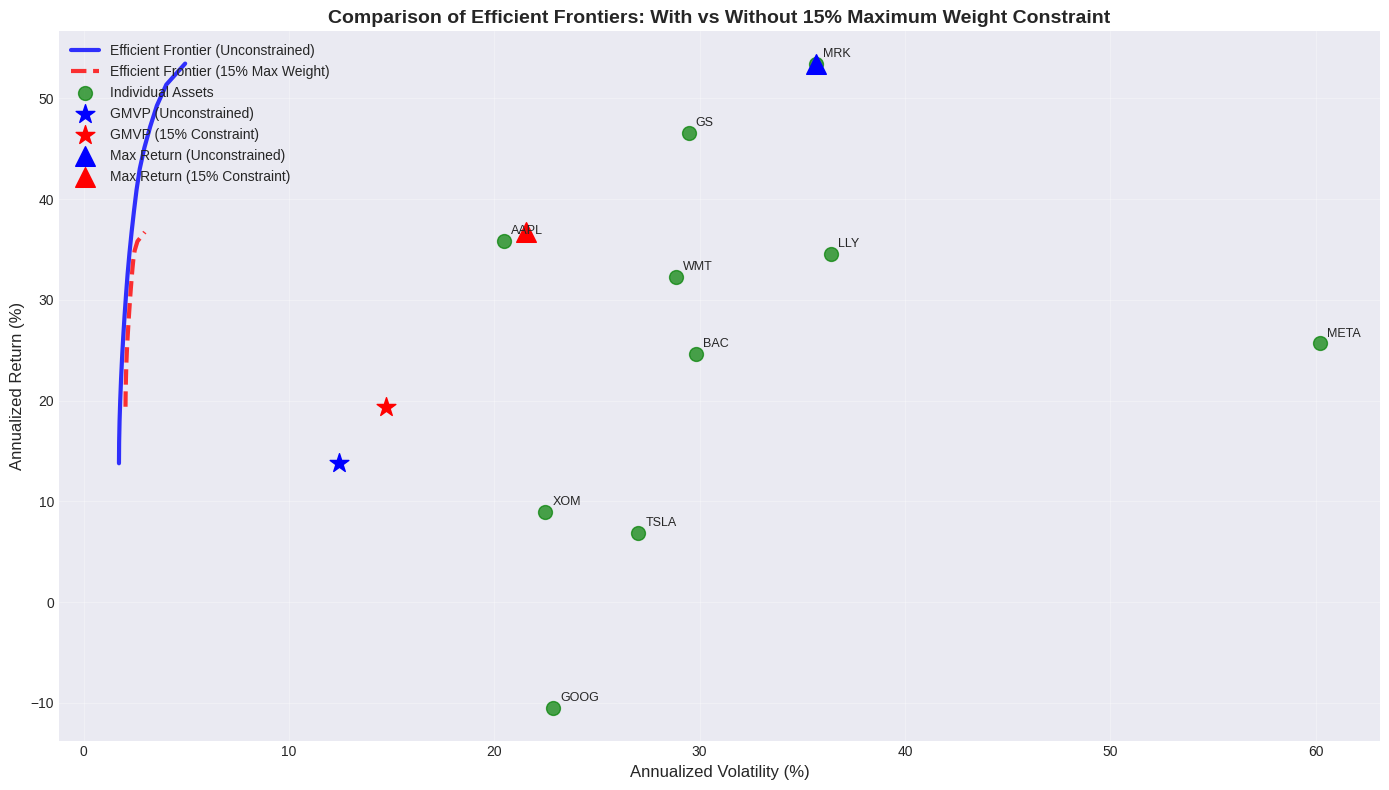

In [149]:
# Generate efficient frontier for UNCONSTRAINED case

bounds_unconstrained = [(0, 1) for _ in range(n_assets)]
constraints_sum = [{'type': 'eq', 'fun': lambda x: np.sum(x) - 1}]

# Find minimum variance portfolio (unconstrained)
min_var_result_unconstrained = minimize(
    fun=portfolio_variance,
    x0=np.ones(n_assets) / n_assets,
    args=(cov_matrix,),
    method='SLSQP',
    bounds=bounds_unconstrained,
    constraints=constraints_sum,
    options={'ftol': 1e-10, 'maxiter': 1000}
)

# Find maximum return portfolio (unconstrained)
def negative_return(weights, mean_returns):
    return -portfolio_return(weights, mean_returns)

max_return_result_unconstrained = minimize(
    fun=negative_return,
    x0=np.ones(n_assets) / n_assets,
    args=(mean_returns,),
    method='SLSQP',
    bounds=bounds_unconstrained,
    constraints=constraints_sum,
    options={'ftol': 1e-10, 'maxiter': 1000}
)

min_return_unconstrained = portfolio_return(min_var_result_unconstrained.x, mean_returns)
max_return_unconstrained = portfolio_return(max_return_result_unconstrained.x, mean_returns)

print(f"  Minimum achievable return (unconstrained): {min_return_unconstrained*100:.4f}% weekly")
print(f"  Maximum achievable return (unconstrained): {max_return_unconstrained*100:.4f}% weekly")

# Generate efficient frontier points for unconstrained case
target_returns_unconstrained = np.linspace(min_return_unconstrained, max_return_unconstrained, 20)
efficient_frontier_unconstrained = []

for target in target_returns_unconstrained:
    constraints = [
        {'type': 'eq', 'fun': lambda x: np.sum(x) - 1},
        {'type': 'eq', 'fun': lambda x: portfolio_return(x, mean_returns) - target}
    ]

    result = minimize(
        fun=portfolio_variance,
        x0=np.ones(n_assets) / n_assets,
        args=(cov_matrix,),
        method='SLSQP',
        bounds=bounds_unconstrained,
        constraints=constraints,
        options={'ftol': 1e-10, 'maxiter': 1000}
    )

    if result.success:
        ret = portfolio_return(result.x, mean_returns)
        vol = np.sqrt(portfolio_variance(result.x, cov_matrix))
        efficient_frontier_unconstrained.append((vol, ret))

# Generate efficient frontier for 15% CONSTRAINT case

bounds_constrained = [(0, 0.15) for _ in range(n_assets)]

# Find minimum variance portfolio (constrained)
min_var_result_constrained = minimize(
    fun=portfolio_variance,
    x0=np.ones(n_assets) / n_assets,
    args=(cov_matrix,),
    method='SLSQP',
    bounds=bounds_constrained,
    constraints=constraints_sum,
    options={'ftol': 1e-10, 'maxiter': 1000}
)

# Find maximum return portfolio (constrained)
max_return_result_constrained = minimize(
    fun=negative_return,
    x0=np.ones(n_assets) / n_assets,
    args=(mean_returns,),
    method='SLSQP',
    bounds=bounds_constrained,
    constraints=constraints_sum,
    options={'ftol': 1e-10, 'maxiter': 1000}
)

min_return_constrained = portfolio_return(min_var_result_constrained.x, mean_returns)
max_return_constrained = portfolio_return(max_return_result_constrained.x, mean_returns)

print(f"  Minimum achievable return (15% constraint): {min_return_constrained*100:.4f}% weekly")
print(f"  Maximum achievable return (15% constraint): {max_return_constrained*100:.4f}% weekly")

# Generate efficient frontier points for constrained case
target_returns_constrained = np.linspace(min_return_constrained, max_return_constrained, 20)
efficient_frontier_constrained = []

for target in target_returns_constrained:
    constraints = [
        {'type': 'eq', 'fun': lambda x: np.sum(x) - 1},
        {'type': 'eq', 'fun': lambda x: portfolio_return(x, mean_returns) - target}
    ]

    result = minimize(
        fun=portfolio_variance,
        x0=np.ones(n_assets) / n_assets,
        args=(cov_matrix,),
        method='SLSQP',
        bounds=bounds_constrained,
        constraints=constraints,
        options={'ftol': 1e-10, 'maxiter': 1000}
    )

    if result.success:
        ret = portfolio_return(result.x, mean_returns)
        vol = np.sqrt(portfolio_variance(result.x, cov_matrix))
        efficient_frontier_constrained.append((vol, ret))

# Convert to arrays for plotting
ef_unconstrained = np.array(efficient_frontier_unconstrained)
ef_constrained = np.array(efficient_frontier_constrained)

# Plot comparison
plt.figure(figsize=(14, 8))

# Plot efficient frontiers
plt.plot(ef_unconstrained[:, 0]*100, ef_unconstrained[:, 1]*52*100,
         'b-', linewidth=3, label='Efficient Frontier (Unconstrained)', alpha=0.8)
plt.plot(ef_constrained[:, 0]*100, ef_constrained[:, 1]*52*100,
         'r--', linewidth=3, label='Efficient Frontier (15% Max Weight)', alpha=0.8)

# Plot individual assets (annualized)
individual_vols = np.sqrt(np.diag(cov_matrix)) * np.sqrt(52) * 100
individual_returns = mean_returns * 52 * 100
plt.scatter(individual_vols, individual_returns, color='green', s=100, alpha=0.7,
           label='Individual Assets')

# Annotate individual assets
for i, ticker in enumerate(tickers):
    plt.annotate(ticker, (individual_vols[i], individual_returns[i]),
                xytext=(5, 5), textcoords='offset points', fontsize=9)

# Mark special portfolios
# GMVP unconstrained
gmvp_vol_unconstrained = np.sqrt(portfolio_variance(min_var_result_unconstrained.x, cov_matrix)) * np.sqrt(52) * 100
gmvp_ret_unconstrained = portfolio_return(min_var_result_unconstrained.x, mean_returns) * 52 * 100
plt.scatter(gmvp_vol_unconstrained, gmvp_ret_unconstrained, color='blue', s=200, marker='*',
           label='GMVP (Unconstrained)')

# GMVP constrained
gmvp_vol_constrained = np.sqrt(portfolio_variance(min_var_result_constrained.x, cov_matrix)) * np.sqrt(52) * 100
gmvp_ret_constrained = portfolio_return(min_var_result_constrained.x, mean_returns) * 52 * 100
plt.scatter(gmvp_vol_constrained, gmvp_ret_constrained, color='red', s=200, marker='*',
           label='GMVP (15% Constraint)')

# Max return portfolios
max_ret_vol_unconstrained = np.sqrt(portfolio_variance(max_return_result_unconstrained.x, cov_matrix)) * np.sqrt(52) * 100
max_ret_ret_unconstrained = max_return_unconstrained * 52 * 100
plt.scatter(max_ret_vol_unconstrained, max_ret_ret_unconstrained, color='blue', s=200, marker='^',
           label='Max Return (Unconstrained)')

max_ret_vol_constrained = np.sqrt(portfolio_variance(max_return_result_constrained.x, cov_matrix)) * np.sqrt(52) * 100
max_ret_ret_constrained = max_return_constrained * 52 * 100
plt.scatter(max_ret_vol_constrained, max_ret_ret_constrained, color='red', s=200, marker='^',
           label='Max Return (15% Constraint)')

# Plot formatting
plt.xlabel('Annualized Volatility (%)', fontsize=12)
plt.ylabel('Annualized Return (%)', fontsize=12)
plt.title('Comparison of Efficient Frontiers: With vs Without 15% Maximum Weight Constraint',
          fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left', fontsize=10)
plt.tight_layout()

# Calculate diversification metrics
def diversification_metrics(weights):
    effective_n = 1 / np.sum(weights**2)
    concentration = np.max(weights)
    return effective_n, concentration

# For unconstrained GMVP
eff_n_uncon, conc_uncon = diversification_metrics(min_var_result_unconstrained.x)

### Step 4

In [150]:
# Define tickers
tickers = ["TSLA", "WMT", "BAC", "GS", "LLY", "MRK", "GOOG", "META", "AAPL", "XOM"]

# DATES
training_start = "2023-07-01"
training_end = "2025-06-30"  # End of training period
test_start = "2025-07-01"     # Start of out-of-sample period
test_end = "2025-09-30"       # End of out-of-sample period

print(f"\nIN-SAMPLE TRAINING PERIOD: {training_start} to {training_end}")
print(f"OUT-OF-SAMPLE TEST PERIOD: {test_start} to {test_end}")


IN-SAMPLE TRAINING PERIOD: 2023-07-01 to 2025-06-30
OUT-OF-SAMPLE TEST PERIOD: 2025-07-01 to 2025-09-30


In [151]:
# Download training data

train_data = yf.download(tickers, start=training_start, end=training_end, interval="1wk")
train_prices = train_data['Close'].dropna()

# Check if we have enough data
if len(train_prices) < 10:
    print("ERROR: Not enough data in training period!")
    print(f"Only {len(train_prices)} weeks of data available.")
    exit()

train_returns = train_prices.pct_change().dropna()
print(f"  Training weeks: {len(train_returns)}")
print(f"  Period: {train_returns.index[0].date()} to {train_returns.index[-1].date()}")

[*********************100%***********************]  10 of 10 completed

  Training weeks: 103
  Period: 2023-07-10 to 2025-06-23


In [152]:
# Calculate portfolio weights from Steps 1 & 2

# Calculate training statistics
train_mean_returns = train_returns.mean().values
train_cov_matrix = train_returns.cov().values
n_assets = len(tickers)

# Portfolio optimization functions
def portfolio_variance(weights, cov_matrix):
    return np.dot(weights.T, np.dot(cov_matrix, weights))

def portfolio_return(weights, mean_returns):
    return np.dot(weights, mean_returns)

def optimize_gmv(mean_returns, cov_matrix, max_weight=None):
    """Optimize for Global Minimum Variance Portfolio"""
    n = len(mean_returns)

    # Set bounds
    if max_weight is None:
        bounds = [(0, 1) for _ in range(n)]  # Step 1: no max constraint
    else:
        bounds = [(0, max_weight) for _ in range(n)]  # Step 2: 15% max constraint

    constraints = [{'type': 'eq', 'fun': lambda x: np.sum(x) - 1}]
    initial_weights = np.ones(n) / n

    # Optimize for minimum variance
    result = minimize(
        fun=portfolio_variance,
        x0=initial_weights,
        args=(cov_matrix,),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints,
        options={'ftol': 1e-10, 'maxiter': 1000}
    )

    return result.x if result.success else None

# Get portfolio weights
weights_step1 = optimize_gmv(train_mean_returns, train_cov_matrix, max_weight=None)
weights_step2 = optimize_gmv(train_mean_returns, train_cov_matrix, max_weight=0.15)

# Display portfolio weights
print("\nPORTFOLIO WEIGHTS:")
print("="*70)
print(f"{'Ticker':<6} {'Step 1 (No Max)':<15} {'Step 2 (15% Max)':<15}")
print("="*70)

for i, ticker in enumerate(tickers):
    print(f"{ticker:<6} {weights_step1[i]:<15.4f} {weights_step2[i]:<15.4f}")
print("="*70)


PORTFOLIO WEIGHTS:
Ticker Step 1 (No Max) Step 2 (15% Max)
TSLA   0.0759          0.1500         
WMT    0.0000          0.1041         
BAC    0.0694          0.1500         
GS     0.0000          0.0284         
LLY    0.0000          0.0760         
MRK    0.0000          0.0415         
GOOG   0.2454          0.1500         
META   0.0000          0.0000         
AAPL   0.3228          0.1500         
XOM    0.2864          0.1500         


In [153]:
# Download out-of-sample data

test_data = yf.download(tickers, start=test_start, end=test_end, interval="1wk")

if test_data.empty or len(test_data) < 4:  # At least 4 weeks (1 month)
    print(f"WARNING: Limited or no data available for {test_start} to {test_end}")
    print("This period may be too recent or data may not be fully available yet.")
    print("Attempting to download daily data instead...")

    # Try daily data as fallback
    test_data = yf.download(tickers, start=test_start, end=test_end, interval="1d")

    if test_data.empty:
        print("ERROR: No data available for the specified out-of-sample period.")
        print("Please check the dates or try a different data source.")
        exit()

test_prices = test_data['Close'].dropna()

# Convert to weekly if we have daily data
if len(test_prices) > 20:  # Likely daily data
    print("Converting daily data to weekly...")
    # Resample to weekly (last observation of each week)
    test_prices = test_prices.resample('W-FRI').last()

test_returns = test_prices.pct_change().dropna()

print(f"✓ Out-of-sample data downloaded successfully")
print(f"  Test periods: {len(test_returns)} weeks/periods")
print(f"  Dates: {test_returns.index[0].date()} to {test_returns.index[-1].date()}")

[*********************100%***********************]  10 of 10 completed

✓ Out-of-sample data downloaded successfully
  Test periods: 13 weeks/periods
  Dates: 2025-07-07 to 2025-09-29


In [154]:
# Calculate out-of-sample performance

def calculate_portfolio_returns(weights, returns_df):
    """Calculate portfolio returns time series"""
    weights = weights / np.sum(weights)  # Ensure weights sum to 1
    # Align weights with return columns
    aligned_weights = pd.Series(weights, index=tickers)
    # Calculate weighted returns
    portfolio_returns = returns_df.multiply(aligned_weights).sum(axis=1)
    return portfolio_returns

# Calculate portfolio returns
portfolio1_returns = calculate_portfolio_returns(weights_step1, test_returns)
portfolio2_returns = calculate_portfolio_returns(weights_step2, test_returns)

# Calculate cumulative returns
portfolio1_cumulative = (1 + portfolio1_returns).cumprod() - 1
portfolio2_cumulative = (1 + portfolio2_returns).cumprod() - 1

# Benchmark: Equal-weighted portfolio
equal_weights = np.ones(n_assets) / n_assets
benchmark_returns = calculate_portfolio_returns(equal_weights, test_returns)
benchmark_cumulative = (1 + benchmark_returns).cumprod() - 1

# Performance metrics function
def calculate_performance_metrics(returns_series, name):
    """Calculate performance metrics"""
    if len(returns_series) == 0:
        return None

    total_return = (1 + returns_series).prod() - 1

    # Handle different frequencies
    periods_per_year = 52 if len(returns_series) > 8 else 12  # Weekly vs monthly

    annualized_return = (1 + total_return) ** (periods_per_year / len(returns_series)) - 1
    volatility = returns_series.std() * np.sqrt(periods_per_year)

    # Sharpe ratio (assuming 4% risk-free rate)
    risk_free_rate = 0.04
    excess_return = annualized_return - risk_free_rate
    sharpe_ratio = excess_return / volatility if volatility > 0 else 0

    # Maximum drawdown
    cumulative = (1 + returns_series).cumprod()
    running_max = cumulative.expanding().max()
    drawdown = (cumulative - running_max) / running_max
    max_drawdown = drawdown.min()

    # Win rate
    win_rate = (returns_series > 0).mean()

    return {
        'Portfolio': name,
        'Total Return': total_return,
        'Annualized Return': annualized_return,
        'Annualized Volatility': volatility,
        'Sharpe Ratio': sharpe_ratio,
        'Max Drawdown': max_drawdown,
        'Win Rate': win_rate,
        'Periods': len(returns_series)
    }

# Calculate metrics
metrics_step1 = calculate_performance_metrics(portfolio1_returns, "Step 1 (No Constraint)")
metrics_step2 = calculate_performance_metrics(portfolio2_returns, "Step 2 (15% Constraint)")
metrics_benchmark = calculate_performance_metrics(benchmark_returns, "Equal-Weight Benchmark")

# Display results
print("\n" + "="*90)
print("OUT-OF-SAMPLE PERFORMANCE COMPARISON")
print(f"Period: {test_returns.index[0].date()} to {test_returns.index[-1].date()}")
print("="*90)

# Create comparison table
metrics_to_show = ['Total Return', 'Annualized Return', 'Annualized Volatility',
                   'Sharpe Ratio', 'Max Drawdown', 'Win Rate']

print(f"\n{'Metric':<25} {'Step 1 Portfolio':<20} {'Step 2 Portfolio':<20} {'Benchmark':<20}")
print("-" * 90)

for metric in metrics_to_show:
    row = [metric]

    for metrics in [metrics_step1, metrics_step2, metrics_benchmark]:
        if metrics and metric in metrics:
            value = metrics[metric]
            if metric in ['Total Return', 'Annualized Return', 'Annualized Volatility', 'Max Drawdown']:
                row.append(f"{value:.2%}")
            elif metric == 'Sharpe Ratio':
                row.append(f"{value:.3f}")
            elif metric == 'Win Rate':
                row.append(f"{value:.1%}")
            else:
                row.append(f"{value:.4f}")
        else:
            row.append("N/A")

    print(f"{row[0]:<25} {row[1]:<20} {row[2]:<20} {row[3]:<20}")

print("="*90)



OUT-OF-SAMPLE PERFORMANCE COMPARISON
Period: 2025-07-07 to 2025-09-29

Metric                    Step 1 Portfolio     Step 2 Portfolio     Benchmark           
------------------------------------------------------------------------------------------
Total Return              18.75%               16.36%               12.58%              
Annualized Return         98.85%               83.33%               60.62%              
Annualized Volatility     16.91%               13.79%               11.58%              
Sharpe Ratio              5.611                5.751                4.890               
Max Drawdown              -3.18%               -3.43%               -2.72%              
Win Rate                  76.9%                76.9%                69.2%               


In [155]:
# Detailed analysis

# Calculate differences
total_return_diff = metrics_step1['Total Return'] - metrics_step2['Total Return']
sharpe_diff = metrics_step1['Sharpe Ratio'] - metrics_step2['Sharpe Ratio']
max_dd_diff = metrics_step1['Max Drawdown'] - metrics_step2['Max Drawdown']

print(f"\nPerformance Differences (Step 1 vs Step 2):")
print(f"  Total Return Difference: {total_return_diff:+.3%}")
print(f"  Sharpe Ratio Difference: {sharpe_diff:+.3f}")
print(f"  Max Drawdown Difference: {max_dd_diff:+.3%}")

# Determine which performed better
print(f"\nKey Findings:")
if total_return_diff > 0:
    print(f"Step 1 Portfolio delivered HIGHER returns by {abs(total_return_diff):.2%}")
else:
    print(f"Step 2 Portfolio delivered HIGHER returns by {abs(total_return_diff):.2%}")

if sharpe_diff > 0:
    print(f"Step 1 Portfolio had BETTER risk-adjusted returns (Sharpe ratio)")
else:
    print(f"Step 2 Portfolio had BETTER risk-adjusted returns (Sharpe ratio)")

if max_dd_diff < 0:  # More negative is worse
    print(f"Step 1 Portfolio had SMALLER maximum drawdown")
else:
    print(f"Step 2 Portfolio had SMALLER maximum drawdown")


Performance Differences (Step 1 vs Step 2):
  Total Return Difference: +2.389%
  Sharpe Ratio Difference: -0.140
  Max Drawdown Difference: +0.256%

Key Findings:
Step 1 Portfolio delivered HIGHER returns by 2.39%
Step 2 Portfolio had BETTER risk-adjusted returns (Sharpe ratio)
Step 2 Portfolio had SMALLER maximum drawdown


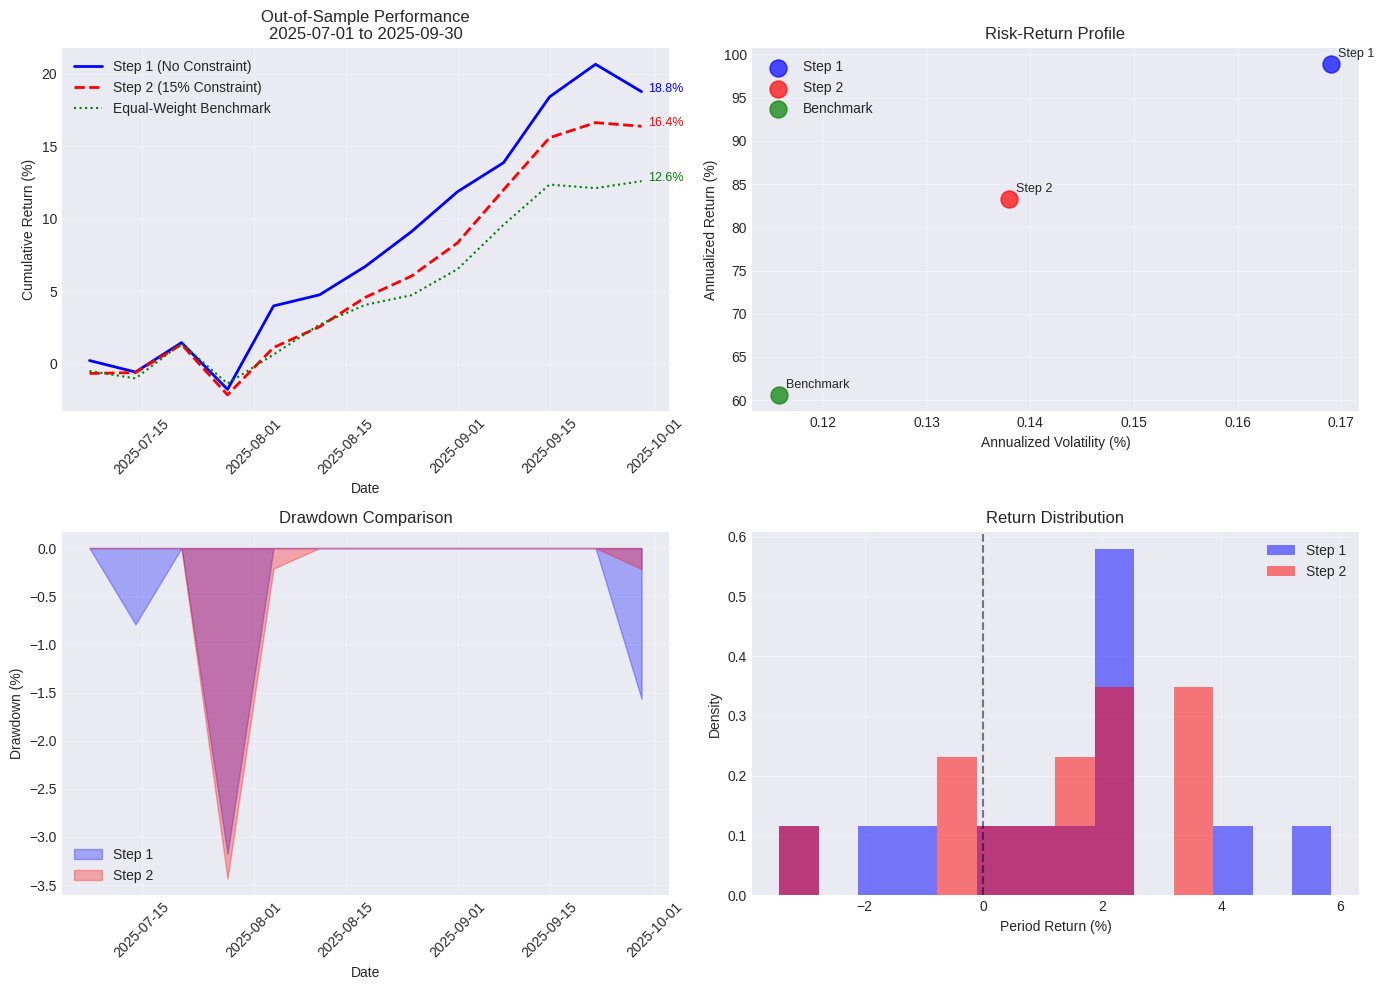

In [156]:
# Visualization

# Create figure
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Cumulative Returns
ax1 = axes[0, 0]
ax1.plot(portfolio1_cumulative.index, portfolio1_cumulative * 100,
         'b-', linewidth=2, label='Step 1 (No Constraint)')
ax1.plot(portfolio2_cumulative.index, portfolio2_cumulative * 100,
         'r--', linewidth=2, label='Step 2 (15% Constraint)')
ax1.plot(benchmark_cumulative.index, benchmark_cumulative * 100,
         'g:', linewidth=1.5, label='Equal-Weight Benchmark')
ax1.set_xlabel('Date')
ax1.set_ylabel('Cumulative Return (%)')
ax1.set_title(f'Out-of-Sample Performance\n{test_start} to {test_end}')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.tick_params(axis='x', rotation=45)

# Annotate final values
final_val1 = portfolio1_cumulative.iloc[-1] * 100
final_val2 = portfolio2_cumulative.iloc[-1] * 100
final_val_bm = benchmark_cumulative.iloc[-1] * 100
ax1.annotate(f'{final_val1:.1f}%',
             xy=(portfolio1_cumulative.index[-1], final_val1),
             xytext=(5, 0), textcoords='offset points',
             fontsize=9, color='blue')
ax1.annotate(f'{final_val2:.1f}%',
             xy=(portfolio2_cumulative.index[-1], final_val2),
             xytext=(5, 0), textcoords='offset points',
             fontsize=9, color='red')
ax1.annotate(f'{final_val_bm:.1f}%',
             xy=(benchmark_cumulative.index[-1], final_val_bm),
             xytext=(5, 0), textcoords='offset points',
             fontsize=9, color='green')

# Plot 2: Risk-Return Scatter
ax2 = axes[0, 1]
portfolios = [metrics_step1, metrics_step2, metrics_benchmark]
colors = ['blue', 'red', 'green']
labels = ['Step 1', 'Step 2', 'Benchmark']

for i, metrics in enumerate(portfolios):
    ax2.scatter(metrics['Annualized Volatility'], metrics['Annualized Return'] * 100,
               s=150, color=colors[i], alpha=0.7, label=labels[i])
    ax2.annotate(labels[i],
                (metrics['Annualized Volatility'], metrics['Annualized Return'] * 100),
                xytext=(5, 5), textcoords='offset points', fontsize=9)

ax2.set_xlabel('Annualized Volatility (%)')
ax2.set_ylabel('Annualized Return (%)')
ax2.set_title('Risk-Return Profile')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Drawdown Comparison
ax3 = axes[1, 0]
def calculate_drawdown(returns):
    cumulative = (1 + returns).cumprod()
    running_max = cumulative.expanding().max()
    drawdown = (cumulative - running_max) / running_max
    return drawdown

drawdown1 = calculate_drawdown(portfolio1_returns)
drawdown2 = calculate_drawdown(portfolio2_returns)

ax3.fill_between(drawdown1.index, drawdown1 * 100, 0,
                alpha=0.3, color='blue', label='Step 1')
ax3.fill_between(drawdown2.index, drawdown2 * 100, 0,
                alpha=0.3, color='red', label='Step 2')
ax3.set_xlabel('Date')
ax3.set_ylabel('Drawdown (%)')
ax3.set_title('Drawdown Comparison')
ax3.legend()
ax3.grid(True, alpha=0.3)
ax3.tick_params(axis='x', rotation=45)

# Plot 4: Weekly Returns Distribution
ax4 = axes[1, 1]
returns_min = min(portfolio1_returns.min(), portfolio2_returns.min()) * 100
returns_max = max(portfolio1_returns.max(), portfolio2_returns.max()) * 100
bins = np.linspace(returns_min, returns_max, 15)

ax4.hist(portfolio1_returns * 100, bins=bins, alpha=0.5,
        color='blue', label='Step 1', density=True)
ax4.hist(portfolio2_returns * 100, bins=bins, alpha=0.5,
        color='red', label='Step 2', density=True)
ax4.axvline(x=0, color='black', linestyle='--', alpha=0.5)
ax4.set_xlabel('Period Return (%)')
ax4.set_ylabel('Density')
ax4.set_title('Return Distribution')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# **Part 2**
 Step 4

In [157]:
import pandas as pd
import numpy as np
from pandas_datareader import data as pdr


# 1. Load Fama-French 5 Factors (Daily)

FF_5f = pdr.DataReader('F-F_Research_Data_5_Factors_2x3_daily', 'famafrench')[0]
FF_5f.index = pd.to_datetime(FF_5f.index)
FF_5f_weekly = FF_5f.resample('W-MON').sum()

# Keep only our period
FF_5f_weekly = FF_5f_weekly.loc[start_date: end_date]

# Convert percent to decimal
FF_5f_weekly = FF_5f_weekly / 100

# Rename columns for convenience
FF_5f_weekly = FF_5f_weekly.rename(columns={
    'Mkt-RF': 'MKT',
    'SMB': 'SMB',
    'HML': 'HML',
    'RMW': 'RMW',
    'CMA': 'CMA',
    'RF': 'RF'
})


# 2. Correlation Matrix of Factors

factors_corr = FF_5f_weekly[['MKT','SMB','HML','RMW','CMA']].corr()

print("Correlation Matrix of Fama-French 5 Factors:")
print(factors_corr)


Correlation Matrix of Fama-French 5 Factors:
          MKT       SMB       HML       RMW       CMA
MKT  1.000000  0.225737 -0.199687 -0.507518  0.010735
SMB  0.225737  1.000000  0.320400 -0.441167  0.103026
HML -0.199687  0.320400  1.000000  0.051638  0.172770
RMW -0.507518 -0.441167  0.051638  1.000000 -0.162435
CMA  0.010735  0.103026  0.172770 -0.162435  1.000000


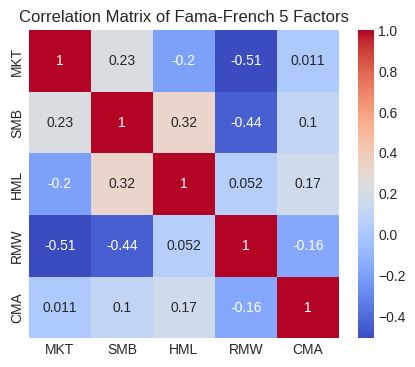

In [158]:
import seaborn as sns

plt.figure(figsize=(5, 4))
sns.heatmap(factors_corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix of Fama-French 5 Factors")
plt.show()

Step 5

In [159]:
# weekly prices & msrp_weights_series from Part 1 Step 2

# 1. Compute portfolio return
msrp_weights_series = pd.Series(msrp_weights, index=tickers)
returns_weekly = prices.pct_change().dropna()

portfolio_ret = returns_weekly @ msrp_weights_series
portfolio_ret.name = "Rp"

# 2. Merge with factor data
factors_full_data = pd.concat([portfolio_ret, FF_5f_weekly], axis=1).dropna()

# Excess return
factors_full_data["Excess_Rp"] = factors_full_data["Rp"] - factors_full_data["RF"]


In [160]:
# train/test split
split_idx = int(len(data) * 0.7)

train_factors = factors_full_data.iloc[:split_idx]
test_factors  = factors_full_data.iloc[split_idx:]

X_train = train_factors[['MKT','SMB','HML','RMW','CMA']]
y_train = train_factors['Excess_Rp']

X_test = test_factors[['MKT','SMB','HML','RMW','CMA']]
y_test = test_factors['Excess_Rp']


In [161]:
import statsmodels.api as sm

X_train_const = sm.add_constant(X_train)
X_test_const  = sm.add_constant(X_test)

ols_model = sm.OLS(y_train, X_train_const).fit()

print("\nOLS Regression Results (Train):")
print(ols_model.summary())



OLS Regression Results (Train):
                            OLS Regression Results                            
Dep. Variable:              Excess_Rp   R-squared:                       0.091
Model:                            OLS   Adj. R-squared:                  0.022
Method:                 Least Squares   F-statistic:                     1.327
Date:                Thu, 12 Feb 2026   Prob (F-statistic):              0.264
Time:                        15:11:00   Log-Likelihood:                 190.08
No. Observations:                  72   AIC:                            -368.2
Df Residuals:                      66   BIC:                            -354.5
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.00

In [162]:
rlm_model = sm.RLM(y_train, X_train_const, M=sm.robust.norms.HuberT()).fit()

print("\nRobust Regression Results (Train):")
print(rlm_model.summary())



Robust Regression Results (Train):
                    Robust linear Model Regression Results                    
Dep. Variable:              Excess_Rp   No. Observations:                   72
Model:                            RLM   Df Residuals:                       66
Method:                          IRLS   Df Model:                            5
Norm:                          HuberT                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Thu, 12 Feb 2026                                         
Time:                        15:11:00                                         
No. Iterations:                    20                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0

In [163]:
from sklearn.metrics import mean_squared_error, r2_score

ols_pred = ols_model.predict(X_test_const)
rlm_pred = rlm_model.predict(X_test_const)

print("\nTest Performance:")
print("OLS RMSE:", np.sqrt(mean_squared_error(y_test, ols_pred)))
print("OLS R²:", r2_score(y_test, ols_pred))

print("Robust RMSE:", np.sqrt(mean_squared_error(y_test, rlm_pred)))
print("Robust R²:", r2_score(y_test, rlm_pred))



Test Performance:
OLS RMSE: 0.03170936750478728
OLS R²: -0.07896842295773099
Robust RMSE: 0.032063790513649645
Robust R²: -0.10322298336369973


In [164]:
train_results = pd.DataFrame({
    "Actual_Excess_Return": y_train,
    "OLS_Predicted": ols_model.predict(X_train_const),
    "Robust_Predicted": rlm_model.predict(X_train_const)
})

print("\nTrain Set Predictions vs Actual:")
print(train_results.head())



Train Set Predictions vs Actual:
            Actual_Excess_Return  OLS_Predicted  Robust_Predicted
Date                                                             
2023-07-10              0.003340       0.004238          0.002559
2023-07-17              0.041604       0.005313          0.004860
2023-07-24             -0.002735       0.001011          0.002626
2023-07-31             -0.017601       0.004370          0.003171
2023-08-07              0.026780      -0.003006         -0.002299


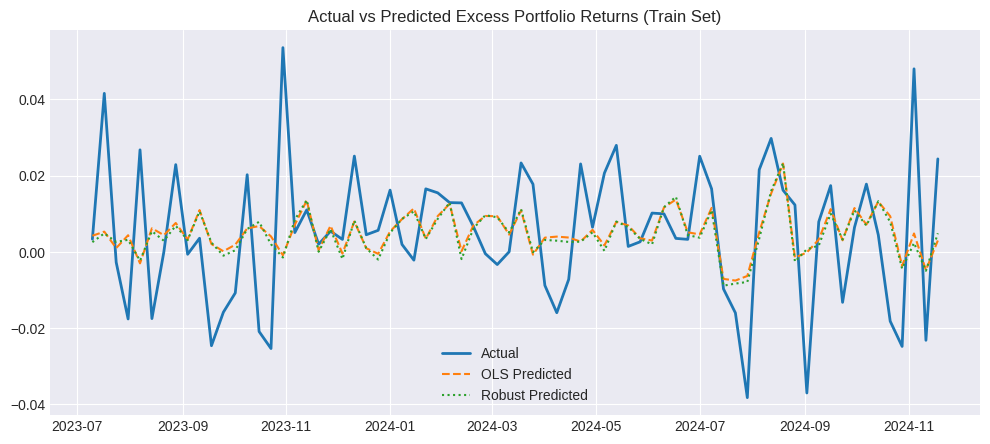

In [165]:
import matplotlib.pyplot as plt

# plot model predict vs. actual on train data
plt.figure(figsize=(12,5))
plt.plot(train_results.index, train_results["Actual_Excess_Return"], label="Actual", linewidth=2)
plt.plot(train_results.index, train_results["OLS_Predicted"], label="OLS Predicted", linestyle="--")
plt.plot(train_results.index, train_results["Robust_Predicted"], label="Robust Predicted", linestyle=":")
plt.title("Actual vs Predicted Excess Portfolio Returns (Train Set)")
plt.legend()
plt.show()

In [166]:
test_results = pd.DataFrame({
    "Actual_Excess_Return": y_test,
    "OLS_Predicted": ols_pred,
    "Robust_Predicted": rlm_pred
})

print("\nTest Set Predictions vs Actual:")
print(test_results.head())



Test Set Predictions vs Actual:
            Actual_Excess_Return  OLS_Predicted  Robust_Predicted
Date                                                             
2024-11-25              0.020422       0.002660          0.000098
2024-12-02              0.007614       0.008973          0.008143
2024-12-09             -0.016292       0.008995          0.007601
2024-12-16             -0.024274       0.002813          0.002201
2024-12-23              0.009285       0.016787          0.016433


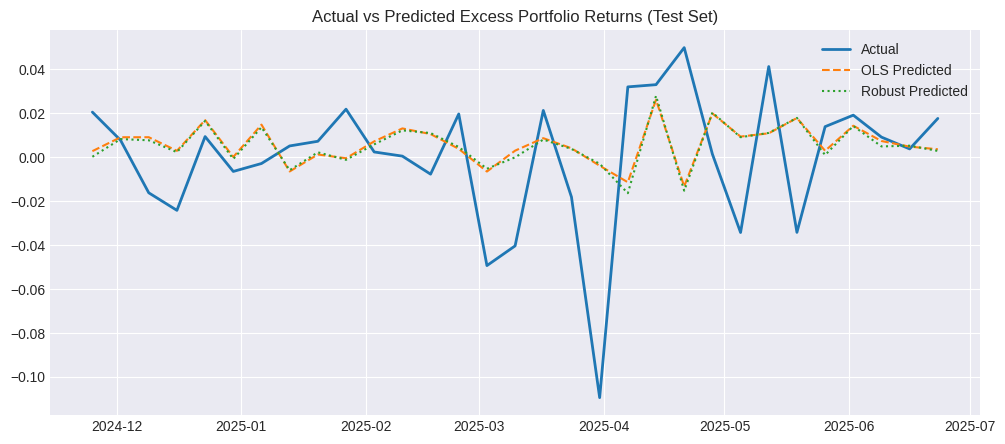

In [167]:
import matplotlib.pyplot as plt

# plot model predict vs. actual on test data
plt.figure(figsize=(12,5))
plt.plot(test_results.index, test_results["Actual_Excess_Return"], label="Actual", linewidth=2)
plt.plot(test_results.index, test_results["OLS_Predicted"], label="OLS Predicted", linestyle="--")
plt.plot(test_results.index, test_results["Robust_Predicted"], label="Robust Predicted", linestyle=":")
plt.title("Actual vs Predicted Excess Portfolio Returns (Test Set)")
plt.legend()
plt.show()


Step 6

In [168]:
coeff_table = pd.DataFrame({
    "OLS Beta": ols_model.params,
    "Robust Beta": rlm_model.params,
    "p-value (OLS)": ols_model.pvalues,
})

print("\nFactor Exposures:")
print(coeff_table)



Factor Exposures:
       OLS Beta  Robust Beta  p-value (OLS)
const  0.004992     0.004261       0.029847
MKT    0.137771     0.176924       0.307198
SMB   -0.203848    -0.250924       0.206337
HML   -0.211317    -0.161193       0.256113
RMW   -0.047426    -0.025047       0.845097
CMA    0.331220     0.326375       0.216708


## **Part 3**

In [169]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Set style for better plots
plt.style.use('seaborn-v0_8-darkgrid')

In [170]:
# Define the securities and period
tickers = ["TSLA", "WMT", "BAC", "GS", "LLY"
            # , "MRK", "GOOG", "META", "AAPL", "XOM"
           ]
start_date = "2023-07-01"
end_date = "2025-06-30"

print("PORTFOLIO OPTIMIZATION FOR 5 ASSETS")
print("=" * 70)
print(f"Tickers: {', '.join(tickers)}")
print(f"Period: {start_date} to {end_date}")
print(f"Frequency: Weekly data")
print("=" * 70)

print("\n1. Downloading data from Yahoo Finance...")

# Download weekly data (adjusted close prices)
data = yf.download(tickers, start=start_date, end=end_date, interval="1wk")

# Extract prices
if 'Adj Close' in data.columns.get_level_values(0):
    prices = data['Adj Close']
elif 'Close' in data.columns.get_level_values(0):
    prices = data['Close']
else:
    raise ValueError("Could not find price data in downloaded data")

# Drop rows with missing values
prices = prices.dropna()
print(f"   Retrieved {len(prices)} weeks of data")
print(f"   Date range: {prices.index[0].date()} to {prices.index[-1].date()}")

# Calculate weekly returns
returns = prices.pct_change().dropna()
print(f"   Returns calculated for {len(returns)} periods")

[*********************100%***********************]  5 of 5 completed

PORTFOLIO OPTIMIZATION FOR 5 ASSETS
Tickers: TSLA, WMT, BAC, GS, LLY
Period: 2023-07-01 to 2025-06-30
Frequency: Weekly data

1. Downloading data from Yahoo Finance...
   Retrieved 104 weeks of data
   Date range: 2023-07-03 to 2025-06-23
   Returns calculated for 103 periods


In [171]:
mean_returns = returns.mean().values
cov_matrix = returns.cov().values
n_assets = len(tickers)

# Create DataFrame for display
stats_df = pd.DataFrame({
    'Ticker': tickers,
    'Mean Weekly Return (%)': (mean_returns * 100).round(4),
    'Annualized Return (%)': (((1 + mean_returns)**52 - 1) * 100).round(2),
    'Weekly Std Dev (%)': (returns.std().values * 100).round(2),
    'Annual Volatility (%)': (np.sqrt(52) * returns.std().values * 100).round(2)
})

print("\nAsset Statistics:")
print(stats_df.to_string(index=False))

print(f"\nCorrelation Matrix (top triangle):")
corr_matrix = returns.corr()
for i in range(n_assets):
    for j in range(i+1, n_assets):
        print(f"   {tickers[i]} - {tickers[j]}: {corr_matrix.iloc[i, j]:.3f}")


Asset Statistics:
Ticker  Mean Weekly Return (%)  Annualized Return (%)  Weekly Std Dev (%)  Annual Volatility (%)
  TSLA                  0.6211                  37.99                4.00                  28.86
   WMT                  0.8959                  59.01                4.09                  29.48
   BAC                  0.6642                  41.09                5.04                  36.38
    GS                  0.4937                  29.19                8.35                  60.20
   LLY                  0.6891                  42.92                2.84                  20.47

Correlation Matrix (top triangle):
   TSLA - WMT: 0.851
   TSLA - BAC: 0.190
   TSLA - GS: 0.252
   TSLA - LLY: 0.331
   WMT - BAC: 0.105
   WMT - GS: 0.371
   WMT - LLY: 0.332
   BAC - GS: 0.007
   BAC - LLY: 0.201
   GS - LLY: 0.228


In [172]:
class PortfolioOptimizer:
    """Portfolio optimization with flexible constraints"""

    def __init__(self, mean_returns, cov_matrix, tickers):
        """
        Initialize the optimizer

        Parameters:
        -----------
        mean_returns : array-like
            Expected returns for each asset
        cov_matrix : array-like
            Covariance matrix of asset returns
        tickers : list
            List of asset tickers
        """
        self.mean_returns = np.array(mean_returns)
        self.cov_matrix = np.array(cov_matrix)
        self.tickers = tickers
        self.n_assets = len(tickers)

    def portfolio_return(self, weights):
        """Calculate portfolio expected return"""
        return np.dot(weights, self.mean_returns)

    def portfolio_variance(self, weights):
        """Calculate portfolio variance"""
        return np.dot(weights.T, np.dot(self.cov_matrix, weights))

    def portfolio_volatility(self, weights):
        """Calculate portfolio volatility (standard deviation)"""
        return np.sqrt(self.portfolio_variance(weights))

    def optimize_gmvp(self, max_weight=1.0, method='SLSQP', verbose=True):
        """
        Optimize for Global Minimum Variance Portfolio with constraints

        Parameters:
        -----------
        max_weight : float
            Maximum weight allowed for any single asset (default: 1.0 = no cap)
        method : str
            Optimization method for scipy.minimize
        verbose : bool
            Whether to print optimization results

        Returns:
        --------
        dict: Optimization results
        """
        # Define constraints
        constraints = [
            {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}  # Weights sum to 1
        ]

        # Define bounds: 0 <= w_i <= max_weight
        bounds = tuple((0, max_weight) for _ in range(self.n_assets))

        # Initial guess (equal weights)
        initial_weights = np.ones(self.n_assets) / self.n_assets

        # Objective function: minimize volatility
        def objective(weights):
            return self.portfolio_volatility(weights)

        # Optimize
        result = minimize(
            fun=objective,
            x0=initial_weights,
            method=method,
            bounds=bounds,
            constraints=constraints,
            options={'ftol': 1e-10, 'maxiter': 1000, 'disp': False}
        )

        if not result.success:
            # Try different initial guess if first fails
            initial_weights = np.random.dirichlet(np.ones(self.n_assets))
            result = minimize(
                fun=objective,
                x0=initial_weights,
                method=method,
                bounds=bounds,
                constraints=constraints,
                options={'ftol': 1e-10, 'maxiter': 2000, 'disp': False}
            )

        optimal_weights = result.x
        optimal_volatility = result.fun
        optimal_variance = optimal_volatility**2
        optimal_return = self.portfolio_return(optimal_weights)

        results = {
            'weights': optimal_weights,
            'volatility': optimal_volatility,
            'variance': optimal_variance,
            'return': optimal_return,
            'success': result.success,
            'message': result.message,
            'n_iter': result.nit
        }

        if verbose:
            self._print_optimization_results(results, max_weight)

        return results

    def monte_carlo_simulation(self, n_simulations=10000, max_weight=1.0, verbose=True):
        """
        Monte Carlo simulation for portfolio optimization

        Parameters:
        -----------
        n_simulations : int
            Number of random portfolios to simulate
        max_weight : float
            Maximum weight allowed for any single asset
        verbose : bool
            Whether to print simulation results

        Returns:
        --------
        dict: Simulation results
        """
        if verbose:
            print(f"\nRunning {n_simulations:,} Monte Carlo simulations...")

        # Pre-allocate arrays
        all_weights = np.zeros((n_simulations, self.n_assets))
        all_variances = np.zeros(n_simulations)
        all_returns = np.zeros(n_simulations)

        for i in tqdm(range(n_simulations), disable=not verbose):
            # Generate random weights with constraints
            weights = self._generate_constrained_weights(max_weight)

            # Store results
            all_weights[i] = weights
            all_variances[i] = self.portfolio_variance(weights)
            all_returns[i] = self.portfolio_return(weights)

        # Find minimum variance portfolio
        min_var_idx = np.argmin(all_variances)

        results = {
            'all_weights': all_weights,
            'all_variances': all_variances,
            'all_returns': all_returns,
            'best_weights': all_weights[min_var_idx],
            'best_variance': all_variances[min_var_idx],
            'best_volatility': np.sqrt(all_variances[min_var_idx]),
            'best_return': all_returns[min_var_idx],
            'min_var_idx': min_var_idx,
            'n_simulations': n_simulations
        }

        if verbose:
            self._print_simulation_results(results, max_weight)

        return results

    def _generate_constrained_weights(self, max_weight):
        """
        Generate random weights with constraints:
        1. Sum to 1
        2. Each weight between 0 and max_weight
        """
        # Method 1: Rejection sampling (simple but may be inefficient for tight constraints)
        while True:
            weights = np.random.dirichlet(np.ones(self.n_assets))
            if np.all(weights <= max_weight + 1e-10):  # Small tolerance
                return weights

        # Alternative: More sophisticated sampling
        # weights = np.random.random(self.n_assets)
        # weights = weights / weights.sum() * max_weight
        # if weights.sum() > 1:
        #     # Adjust to sum to 1
        #     weights = weights / weights.sum()
        # return weights

    def _print_optimization_results(self, results, max_weight):
        """Print optimization results in a formatted way"""
        print("\n" + "="*60)
        print(f"ANALYTICAL OPTIMIZATION RESULTS (max weight: {max_weight*100:.0f}%)")
        print("="*60)

        print(f"\nOptimization successful: {results['success']}")
        if not results['success']:
            print(f"Message: {results['message']}")

        print("\nOPTIMAL WEIGHTS:")
        print("-" * 40)
        total_weight = 0
        for i, ticker in enumerate(self.tickers):
            weight = results['weights'][i]
            if weight > 0.0001:  # Show non-negligible weights
                print(f"{ticker:<6}: {weight:>8.4f} ({weight*100:>6.2f}%)")
                total_weight += weight

        print("-" * 40)
        print(f"{'Total':<6}: {total_weight:>8.4f} ({total_weight*100:>6.2f}%)")

        print("\nPORTFOLIO STATISTICS:")
        print("-" * 40)
        print(f"Expected Return (weekly):  {results['return']:.6f} ({results['return']*100:.4f}%)")
        print(f"Volatility (weekly):       {results['volatility']:.6f} ({results['volatility']*100:.4f}%)")
        print(f"Variance (weekly):         {results['variance']:.8f}")
        print(f"Sharpe Ratio (weekly):     {results['return']/results['volatility']:.4f}")

    def _print_simulation_results(self, results, max_weight):
        """Print simulation results in a formatted way"""
        print("\n" + "="*60)
        print(f"MONTE CARLO SIMULATION RESULTS ({results['n_simulations']:,} sims, max weight: {max_weight*100:.0f}%)")
        print("="*60)

        print("\nBEST PORTFOLIO FROM SIMULATIONS:")
        print("-" * 40)
        total_weight = 0
        for i, ticker in enumerate(self.tickers):
            weight = results['best_weights'][i]
            if weight > 0.0001:
                print(f"{ticker:<6}: {weight:>8.4f} ({weight*100:>6.2f}%)")
                total_weight += weight

        print("-" * 40)
        print(f"{'Total':<6}: {total_weight:>8.4f} ({total_weight*100:>6.2f}%)")

        print("\nPORTFOLIO STATISTICS:")
        print("-" * 40)
        print(f"Expected Return (weekly):  {results['best_return']:.6f} ({results['best_return']*100:.4f}%)")
        print(f"Volatility (weekly):       {results['best_volatility']:.6f} ({results['best_volatility']*100:.4f}%)")
        print(f"Variance (weekly):         {results['best_variance']:.8f}")
        print(f"Sharpe Ratio (weekly):     {results['best_return']/results['best_volatility']:.4f}")


In [173]:
def compare_methods(optimizer, max_weight=1.0, n_simulations=50000):
    """
    Compare analytical optimization vs Monte Carlo simulation
    Parameters:
    -----------
    optimizer : PortfolioOptimizer
        Optimizer instance
    max_weight : float
        Maximum weight per asset
    n_simulations : int
        Number of Monte Carlo simulations

    Returns:
    --------
    tuple: (opt_results, sim_results, comparison_df)
    """
    print("COMPARISON: ANALYTICAL OPTIMIZATION vs MONTE CARLO SIMULATION")
    print(f"CONSTRAINTS: No short sales, sum to 1, max {max_weight*100:.0f}% per asset")
    print("="*80)

    # Run analytical optimization
    print("\n1. ANALYTICAL OPTIMIZATION (SLSQP):")
    opt_results = optimizer.optimize_gmvp(max_weight=max_weight, verbose=True)

    # Run Monte Carlo simulation
    print("\n2. MONTE CARLO SIMULATION:")
    sim_results = optimizer.monte_carlo_simulation(
        n_simulations=n_simulations,
        max_weight=max_weight,
        verbose=True
    )

    # Compare results
    print("\n3. COMPARISON:")
    print("-" * 60)

    comparison_data = []
    for i, ticker in enumerate(optimizer.tickers):
        opt_weight = opt_results['weights'][i]
        sim_weight = sim_results['best_weights'][i]
        diff = sim_weight - opt_weight
        diff_pct = diff / opt_weight * 100 if opt_weight > 0 else 0

        comparison_data.append({
            'Asset': ticker,
            'Optimization': opt_weight,
            'Simulation': sim_weight,
            'Difference': diff,
            'Diff (%)': diff_pct
        })

    comparison_df = pd.DataFrame(comparison_data)

    # Add portfolio statistics
    stats_data = {
        'Metric': ['Expected Return', 'Volatility', 'Variance'],
        'Optimization': [
            opt_results['return'],
            opt_results['volatility'],
            opt_results['variance']
        ],
        'Simulation': [
            sim_results['best_return'],
            sim_results['best_volatility'],
            sim_results['best_variance']
        ]
    }
    stats_df = pd.DataFrame(stats_data)

    # Print comparison
    print("\nWEIGHTS COMPARISON:")
    print(comparison_df.to_string(index=False, float_format=lambda x: f'{x:.6f}'))

    print("\nPORTFOLIO STATISTICS COMPARISON:")
    print(stats_df.to_string(index=False, float_format=lambda x: f'{x:.8f}'))

    # Calculate overall differences
    weight_diff_avg = np.mean(np.abs(comparison_df['Difference']))
    weight_diff_max = np.max(np.abs(comparison_df['Difference']))
    var_diff_pct = (sim_results['best_variance'] - opt_results['variance']) / opt_results['variance'] * 100

    print(f"\nSUMMARY METRICS:")
    print(f"Average absolute weight difference: {weight_diff_avg:.6f}")
    print(f"Maximum absolute weight difference: {weight_diff_max:.6f}")
    print(f"Variance difference: {var_diff_pct:.4f}%")

    if var_diff_pct < 1.0:
        print(f"\n✓ Monte Carlo found a solution within 1% of optimal variance")
    else:
        print(f"\n⚠ Monte Carlo solution differs by {var_diff_pct:.2f}% from optimal")

    return opt_results, sim_results, comparison_df, stats_df


In [174]:
def plot_portfolio_comparison(opt_weights, sim_weights, tickers, max_weight):
    """
    Plot comparison of optimization vs simulation weights
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Bar chart comparison
    x = np.arange(len(tickers))
    width = 0.35

    axes[0].bar(x - width/2, opt_weights, width, label='Optimization', alpha=0.8, color='steelblue')
    axes[0].bar(x + width/2, sim_weights, width, label='Simulation', alpha=0.8, color='coral')

    # Add max weight line
    axes[0].axhline(y=max_weight, color='red', linestyle='--', alpha=0.5, label=f'Max weight ({max_weight*100:.0f}%)')

    axes[0].set_xlabel('Assets')
    axes[0].set_ylabel('Weight')
    axes[0].set_title(f'Portfolio Weights Comparison (Max: {max_weight*100:.0f}%)')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(tickers, rotation=45)
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Difference plot
    differences = sim_weights - opt_weights
    colors = ['green' if diff >= 0 else 'red' for diff in differences]

    axes[1].bar(tickers, differences, color=colors, alpha=0.7)
    axes[1].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
    axes[1].set_xlabel('Assets')
    axes[1].set_ylabel('Weight Difference (Sim - Opt)')
    axes[1].set_title('Weight Differences')
    axes[1].set_xticklabels(tickers, rotation=45)
    axes[1].grid(True, alpha=0.3)

    # Add value labels on bars
    for i, (ticker, diff) in enumerate(zip(tickers, differences)):
        axes[1].text(i, diff + (0.001 if diff >= 0 else -0.003),
                    f'{diff:.4f}', ha='center', va='bottom' if diff >= 0 else 'top',
                    fontsize=9)

    plt.tight_layout()
    plt.show()


In [175]:
def convergence_analysis(optimizer, max_weight=1.0, max_simulations=100000, checkpoints=20):
    """
    Analyze Monte Carlo convergence with increasing simulations
    """
    print(f"MONTE CARLO CONVERGENCE ANALYSIS (max weight: {max_weight*100:.0f}%)")

    # Get analytical optimum for reference
    opt_results = optimizer.optimize_gmvp(max_weight=max_weight, verbose=False)
    analytical_weights = opt_results['weights']
    analytical_variance = opt_results['variance']

    # Test different simulation sizes
    simulation_sizes = np.logspace(3, np.log10(max_simulations), checkpoints).astype(int)
    simulation_sizes = np.unique(simulation_sizes)

    convergence_data = []

    for n_sims in tqdm(simulation_sizes, desc="Convergence analysis"):
        # Run Monte Carlo
        sim_results = optimizer.monte_carlo_simulation(
            n_simulations=n_sims,
            max_weight=max_weight,
            verbose=False
        )

        # Calculate convergence metrics
        weight_diff = np.abs(sim_results['best_weights'] - analytical_weights)
        var_diff_pct = (sim_results['best_variance'] - analytical_variance) / analytical_variance * 100

        convergence_data.append({
            'n_simulations': n_sims,
            'variance': sim_results['best_variance'],
            'variance_diff_pct': var_diff_pct,
            'avg_weight_diff': np.mean(weight_diff),
            'max_weight_diff': np.max(weight_diff),
            'weights': sim_results['best_weights'].copy()
        })

    convergence_df = pd.DataFrame(convergence_data)

    # Plot convergence
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    # Variance convergence
    axes[0, 0].semilogx(convergence_df['n_simulations'], convergence_df['variance'],
                       'b-o', linewidth=2, markersize=5)
    axes[0, 0].axhline(y=analytical_variance, color='r', linestyle='--',
                      linewidth=2, label=f'Analytical: {analytical_variance:.8f}')
    axes[0, 0].set_xlabel('Number of Simulations')
    axes[0, 0].set_ylabel('Portfolio Variance')
    axes[0, 0].set_title('Variance Convergence')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    # Weight difference convergence
    axes[0, 1].semilogx(convergence_df['n_simulations'], convergence_df['avg_weight_diff'],
                       'r-o', linewidth=2, markersize=5, label='Average')
    axes[0, 1].semilogx(convergence_df['n_simulations'], convergence_df['max_weight_diff'],
                       'g-o', linewidth=2, markersize=5, label='Maximum')
    axes[0, 1].set_xlabel('Number of Simulations')
    axes[0, 1].set_ylabel('Weight Absolute Difference')
    axes[0, 1].set_title('Weight Convergence')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

    # Variance difference percentage
    axes[1, 0].semilogx(convergence_df['n_simulations'], convergence_df['variance_diff_pct'],
                       'm-o', linewidth=2, markersize=5)
    axes[1, 0].axhline(y=0, color='r', linestyle='--', linewidth=2)
    axes[1, 0].set_xlabel('Number of Simulations')
    axes[1, 0].set_ylabel('Variance Difference (%)')
    axes[1, 0].set_title('Percentage Difference from Optimum')
    axes[1, 0].grid(True, alpha=0.3)

    # Individual weight convergence (last subplot)
    final_weights = convergence_df.iloc[-1]['weights']
    x = np.arange(len(optimizer.tickers))
    width = 0.35

    axes[1, 1].bar(x - width/2, analytical_weights, width, label='Analytical', alpha=0.7)
    axes[1, 1].bar(x + width/2, final_weights, width, label=f'MC ({convergence_df.iloc[-1]["n_simulations"]:,} sims)', alpha=0.7)
    axes[1, 1].set_xlabel('Assets')
    axes[1, 1].set_ylabel('Weight')
    axes[1, 1].set_title('Final Weight Comparison')
    axes[1, 1].set_xticks(x)
    axes[1, 1].set_xticklabels(optimizer.tickers, rotation=45)
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Print convergence statistics
    print("\nCONVERGENCE STATISTICS:")
    print("-" * 60)
    final_row = convergence_df.iloc[-1]
    print(f"Final simulation count: {final_row['n_simulations']:,}")
    print(f"Final variance: {final_row['variance']:.8f}")
    print(f"Variance difference from optimum: {final_row['variance_diff_pct']:.4f}%")
    print(f"Average weight difference: {final_row['avg_weight_diff']:.6f}")
    print(f"Maximum weight difference: {final_row['max_weight_diff']:.6f}")

    return convergence_df


In [176]:
# Create optimizer instance
optimizer = PortfolioOptimizer(mean_returns, cov_matrix, tickers)
all_results = {}
def final_presentation(scenario):
    print(f"SCENARIO: {scenario['name']}")

    max_weight = scenario['max_weight']
    # Compare analytical optimization vs Monte Carlo
    opt_results, sim_results, comparison_df, stats_df = compare_methods(
        optimizer=optimizer,
        max_weight=max_weight,
        n_simulations=50000
    )

    # Plot comparison
    plot_portfolio_comparison(
        opt_results['weights'],
        sim_results['best_weights'],
        tickers,
        max_weight
    )

    # Store results
    all_results[scenario['name']] = {
        'opt_results': opt_results,
        'sim_results': sim_results,
        'comparison_df': comparison_df,
        'stats_df': stats_df
    }

    # Run convergence analysis
    convergence_df = convergence_analysis(
        optimizer=optimizer,
        max_weight=max_weight,
        max_simulations=100000,
        checkpoints=15
    )

In [188]:
# Final summary comparison
print("\n" + "="*80)
print("FINAL SUMMARY: COMPARISON OF CONSTRAINT SCENARIOS")
print("="*80)

summary_data = []
for scenario_name, results in all_results.items():
    opt = results['opt_results']
    sim = results['sim_results']

    summary_data.append({
        'Scenario': scenario_name,
        'Opt Return': opt['return'],
        'Opt Volatility': opt['volatility'],
        'Opt Variance': opt['variance'],
        'MC Return': sim['best_return'],
        'MC Volatility': sim['best_volatility'],
        'MC Variance': sim['best_variance'],
        'Weight Diff (avg)': np.mean(np.abs(sim['best_weights'] - opt['weights'])),
        'Var Diff (%)': (sim['best_variance'] - opt['variance']) / opt['variance'] * 100
    })

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False, float_format=lambda x: f'{x:.6f}'))


FINAL SUMMARY: COMPARISON OF CONSTRAINT SCENARIOS
                            Scenario  Opt Return  Opt Volatility  Opt Variance  MC Return  MC Volatility  MC Variance  Weight Diff (avg)  Var Diff (%)
No constraints except no short sales    0.007045        0.025089      0.000629   0.007002       0.025107     0.000630           0.012771      0.143766
                   30% cap per asset    0.007106        0.027269      0.000744   0.007059       0.027277     0.000744           0.005862      0.057417


SCENARIO: No constraints except no short sales
COMPARISON: ANALYTICAL OPTIMIZATION vs MONTE CARLO SIMULATION
CONSTRAINTS: No short sales, sum to 1, max 100% per asset

1. ANALYTICAL OPTIMIZATION (SLSQP):

ANALYTICAL OPTIMIZATION RESULTS (max weight: 100%)

Optimization successful: True

OPTIMAL WEIGHTS:
----------------------------------------
TSLA  :   0.0950 (  9.50%)
WMT   :   0.1305 ( 13.05%)
BAC   :   0.1521 ( 15.21%)
GS    :   0.0067 (  0.67%)
LLY   :   0.6156 ( 61.56%)
----------------------------------------
Total :   1.0000 (100.00%)

PORTFOLIO STATISTICS:
----------------------------------------
Expected Return (weekly):  0.007045 (0.7045%)
Volatility (weekly):       0.025089 (2.5089%)
Variance (weekly):         0.00062946
Sharpe Ratio (weekly):     0.2808

2. MONTE CARLO SIMULATION:

Running 50,000 Monte Carlo simulations...


100%|██████████| 50000/50000 [00:01<00:00, 42534.70it/s]



MONTE CARLO SIMULATION RESULTS (50,000 sims, max weight: 100%)

BEST PORTFOLIO FROM SIMULATIONS:
----------------------------------------
TSLA  :   0.1258 ( 12.58%)
WMT   :   0.1193 ( 11.93%)
BAC   :   0.1406 ( 14.06%)
GS    :   0.0079 (  0.79%)
LLY   :   0.6064 ( 60.64%)
----------------------------------------
Total :   1.0000 (100.00%)

PORTFOLIO STATISTICS:
----------------------------------------
Expected Return (weekly):  0.007002 (0.7002%)
Volatility (weekly):       0.025107 (2.5107%)
Variance (weekly):         0.00063036
Sharpe Ratio (weekly):     0.2789

3. COMPARISON:
------------------------------------------------------------

WEIGHTS COMPARISON:
Asset  Optimization  Simulation  Difference  Diff (%)
 TSLA      0.095010    0.125786    0.030775 32.391546
  WMT      0.130517    0.119307   -0.011211 -8.589370
  BAC      0.152109    0.140644   -0.011465 -7.537656
   GS      0.006741    0.007894    0.001153 17.101301
  LLY      0.615622    0.606370   -0.009252 -1.502883

PORTFOL

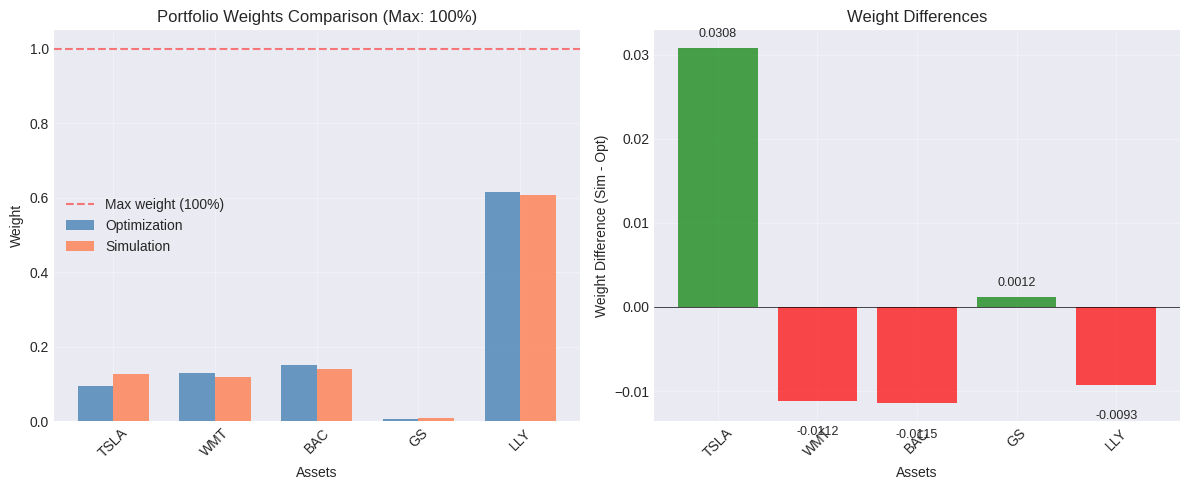

MONTE CARLO CONVERGENCE ANALYSIS (max weight: 100%)


Convergence analysis: 100%|██████████| 15/15 [00:08<00:00,  1.73it/s]


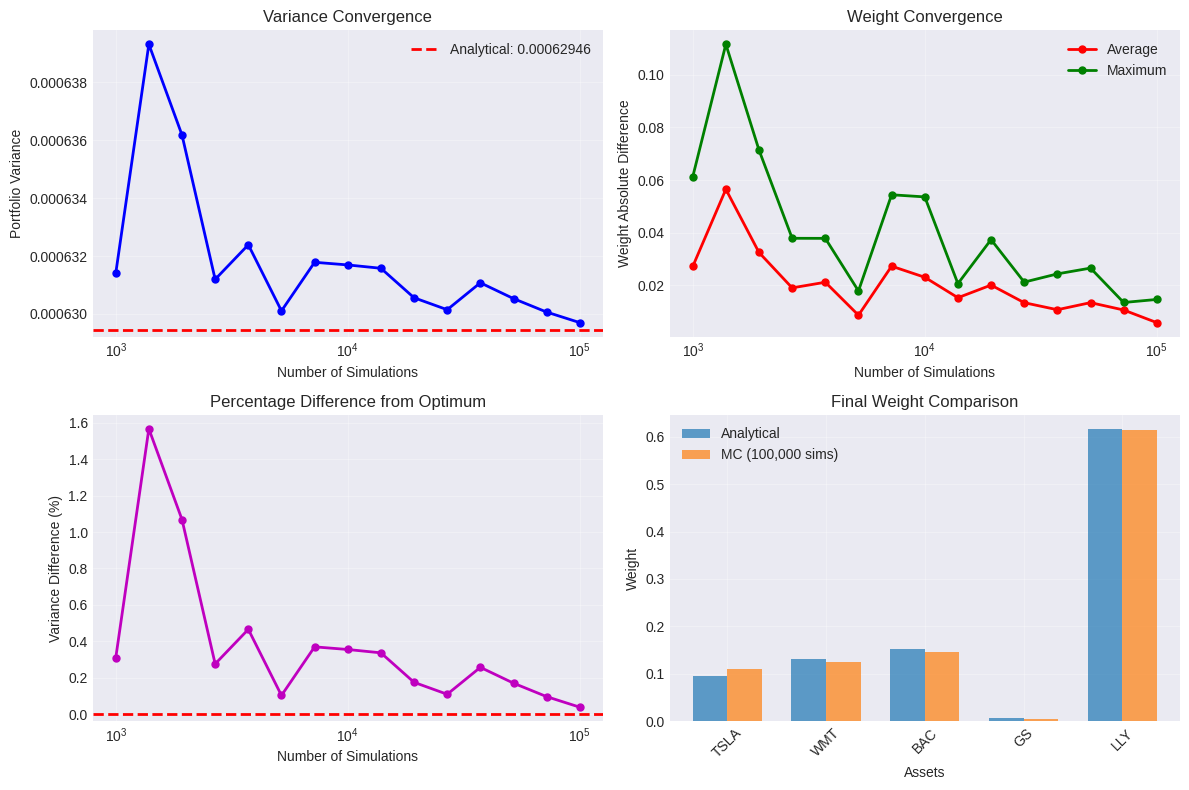


CONVERGENCE STATISTICS:
------------------------------------------------------------
Final simulation count: 100,000
Final variance: 0.00062970
Variance difference from optimum: 0.0382%
Average weight difference: 0.005869
Maximum weight difference: 0.014673


In [177]:
# Step 7
final_presentation({'name': 'No constraints except no short sales', 'max_weight': 1.0})

SCENARIO: 30% cap per asset
COMPARISON: ANALYTICAL OPTIMIZATION vs MONTE CARLO SIMULATION
CONSTRAINTS: No short sales, sum to 1, max 30% per asset

1. ANALYTICAL OPTIMIZATION (SLSQP):

ANALYTICAL OPTIMIZATION RESULTS (max weight: 30%)

Optimization successful: True

OPTIMAL WEIGHTS:
----------------------------------------
TSLA  :   0.1850 ( 18.50%)
WMT   :   0.2276 ( 22.76%)
BAC   :   0.2532 ( 25.32%)
GS    :   0.0342 (  3.42%)
LLY   :   0.3000 ( 30.00%)
----------------------------------------
Total :   1.0000 (100.00%)

PORTFOLIO STATISTICS:
----------------------------------------
Expected Return (weekly):  0.007106 (0.7106%)
Volatility (weekly):       0.027269 (2.7269%)
Variance (weekly):         0.00074361
Sharpe Ratio (weekly):     0.2606

2. MONTE CARLO SIMULATION:

Running 50,000 Monte Carlo simulations...


100%|██████████| 50000/50000 [00:16<00:00, 3007.51it/s]



MONTE CARLO SIMULATION RESULTS (50,000 sims, max weight: 30%)

BEST PORTFOLIO FROM SIMULATIONS:
----------------------------------------
TSLA  :   0.1878 ( 18.78%)
WMT   :   0.2130 ( 21.30%)
BAC   :   0.2579 ( 25.79%)
GS    :   0.0413 (  4.13%)
LLY   :   0.3000 ( 30.00%)
----------------------------------------
Total :   1.0000 (100.00%)

PORTFOLIO STATISTICS:
----------------------------------------
Expected Return (weekly):  0.007059 (0.7059%)
Volatility (weekly):       0.027277 (2.7277%)
Variance (weekly):         0.00074404
Sharpe Ratio (weekly):     0.2588

3. COMPARISON:
------------------------------------------------------------

WEIGHTS COMPARISON:
Asset  Optimization  Simulation  Difference  Diff (%)
 TSLA      0.184990    0.187809    0.002819  1.523760
  WMT      0.227620    0.212983   -0.014638 -6.430730
  BAC      0.253159    0.257938    0.004778  1.887530
   GS      0.034230    0.041287    0.007057 20.616972
  LLY      0.300000    0.299983   -0.000017 -0.005579

PORTFOLI

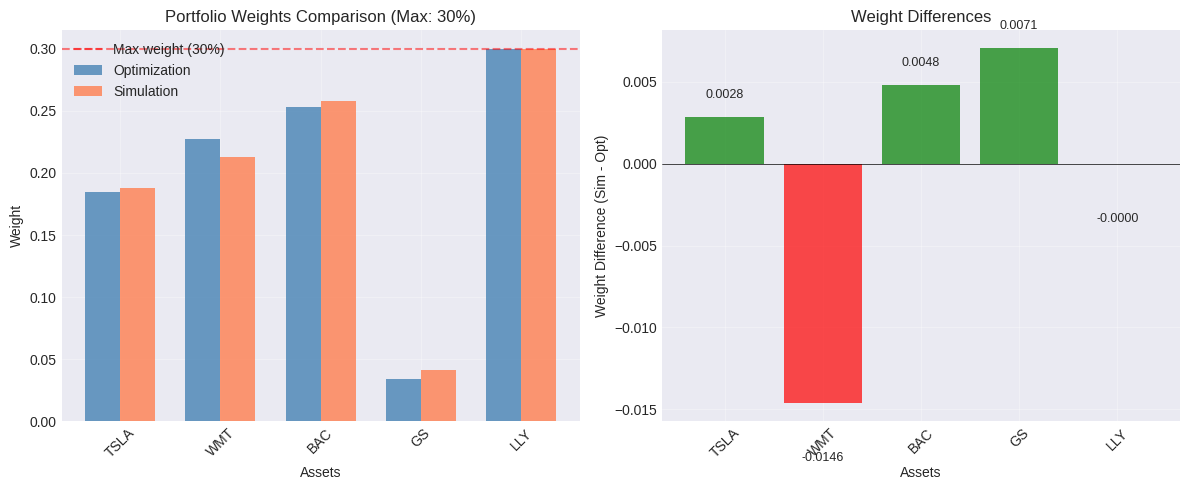

MONTE CARLO CONVERGENCE ANALYSIS (max weight: 30%)


Convergence analysis: 100%|██████████| 15/15 [01:55<00:00,  7.70s/it]


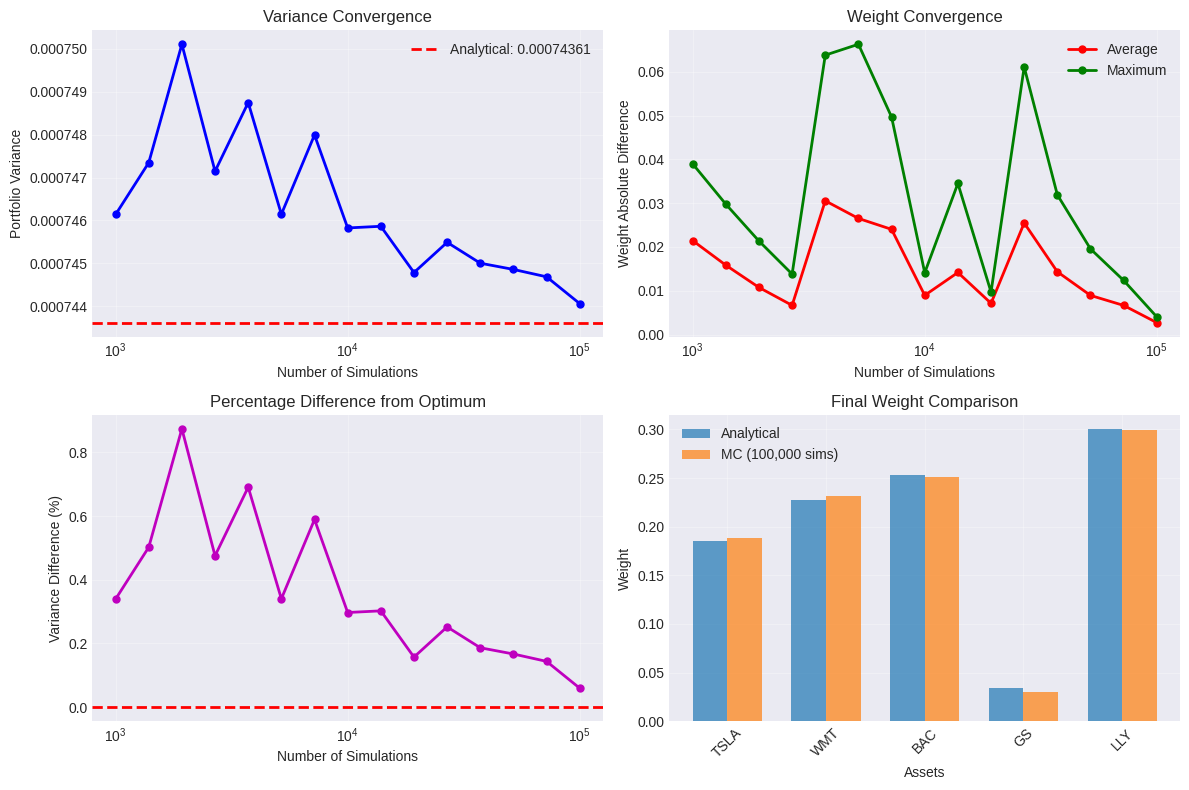


CONVERGENCE STATISTICS:
------------------------------------------------------------
Final simulation count: 100,000
Final variance: 0.00074406
Variance difference from optimum: 0.0596%
Average weight difference: 0.002722
Maximum weight difference: 0.004034


In [178]:
# Step 8
final_presentation({'name': '30% cap per asset', 'max_weight': 0.3})

In [192]:
print("\n" + "="*80)